# Regresja liniowa – idea i założenia

**Plan notatnika:**
1. Idea regresji liniowej
2. Pierwszy model
3. Reszty i metoda najmniejszych kwadratów
4. Dwie metody znajdowania parametrów
5. Założenia modelu i diagnostyka reszt
6. Pułapka ekstrapolacji
7. Zalety i wady
8. Podsumowanie

## 1. Idea regresji liniowej

**Regresja liniowa** opisuje zależność między cechą (lub cechami) a wynikiem liczbowym za pomocą **prostej**. Używamy jej, aby:
- **przewidywać** wartości liczbowe (cena, sprzedaż, czas),
- **zrozumieć**, jak cechy wpływają na wynik.

Dla jednej cechy $x$ model ma postać:

$$y = w_0 + w_1 x + \varepsilon$$

- $w_1$ – **nachylenie** prostej: o ile średnio zmienia się $y$, gdy $x$ rośnie o 1,
- $w_0$ – **wyraz wolny** (*intercept*): wartość $y$ dla $x = 0$,
- $\varepsilon$ – **błąd losowy**: to, czego model nie potrafi wyjaśnić.

Model uczy się parametrów $w_0$ i $w_1$ z danych. Działa najlepiej, gdy zależność jest w przybliżeniu liniowa.

## 2. Pierwszy model

Wygenerujemy dane, w których **znamy prawdziwą zależność**: $y = 4 + 3x + \text{szum}$. Sprawdzimy, czy model ją odtworzy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

rng = np.raandom.default_rng(42)
X = 2 * rng.random((100, 1))                  # 100 losowych liczb z przedziału [0, 2)
y = 4 + 3 * X[:, 0] + rng.normal(size=100)    # prawdziwe parametry: w0 = 4, w1 = 3, plus szum

model = LinearRegression()
model.fit(X, y)

print(f'w0 (intercept_) = {model.intercept_:.2f}')
print(f'w1 (coef_)      = {model.coef_[0]:.2f}')

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


w0 (intercept_) = 3.95
w1 (coef_)      = 3.04


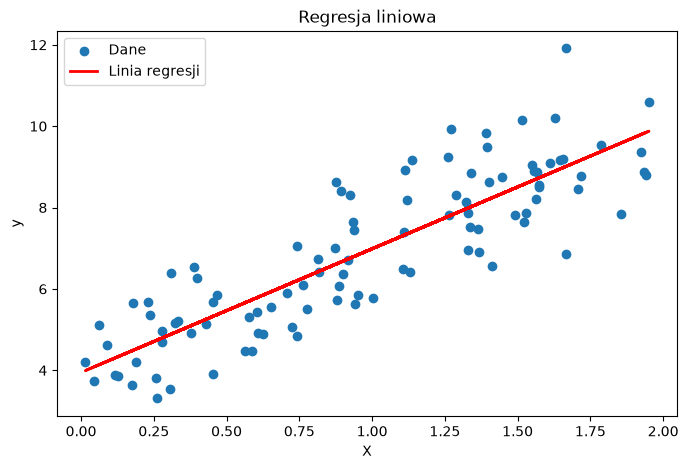

In [4]:
y_pred = model.predict(X)

plt.figure(figsize=(8, 5))
plt.scatter(X, y, label='Dane')
plt.plot(X, y_pred, color='red', linewidth=2, label='Linia regresji')
plt.title('Regresja liniowa')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.show()

Model znalazł parametry bliskie prawdziwym (4 i 3). Różnice wynikają z szumu w danych.

## 3. Reszty i metoda najmniejszych kwadratów

Różnica między wartością rzeczywistą a przewidywaną to **reszta** (*residual*):

$$reszta_i = y_i - \hat{y}_i$$

Na wykresie reszty to pionowe odcinki między punktem a prostą.

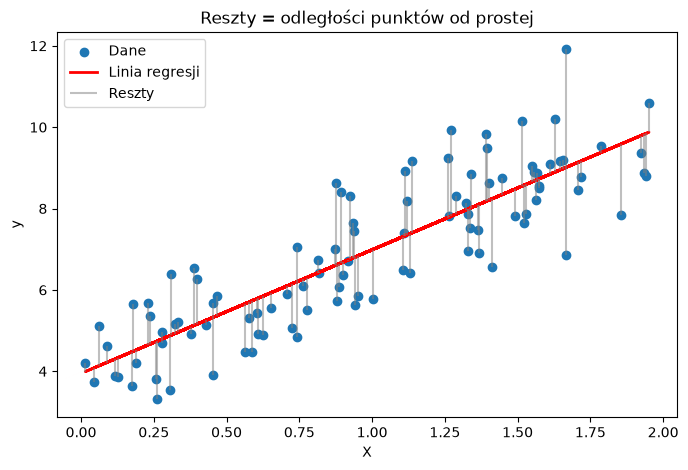

In [5]:
residuals = y - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(X, y, label='Dane')
plt.plot(X, y_pred, color='red', linewidth=2, label='Linia regresji')
plt.vlines(X[:, 0], y_pred, y, color='gray', alpha=0.5, label='Reszty')
plt.title('Reszty = odległości punktów od prostej')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.show()

**Metoda najmniejszych kwadratów** wybiera taką prostą, dla której średni kwadrat reszt jest jak najmniejszy:

$$MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

Sprawdźmy to: porównamy błąd prostej dopasowanej przez model z dwiema innymi prostymi.

In [6]:
def mse(w0, w1):
    return np.mean((y - (w0 + w1 * X[:, 0])) ** 2)

print(f'Prosta dopasowana (w0={model.intercept_:.2f}, w1={model.coef_[0]:.2f}): MSE = {mse(model.intercept_, model.coef_[0]):.3f}')
print(f'Prosta w0=6, w1=1: MSE = {mse(6, 1):.3f}')
print(f'Prosta w0=2, w1=4: MSE = {mse(2, 4):.3f}')

Prosta dopasowana (w0=3.95, w1=3.04): MSE = 0.959
Prosta w0=6, w1=1: MSE = 2.195
Prosta w0=2, w1=4: MSE = 2.258


## 4. Dwie metody znajdowania parametrów

Parametry minimalizujące MSE można znaleźć na dwa sposoby. Poznamy je w kolejnych notatnikach:

| Metoda | Idea | Kiedy |
|---|---|---|
| **Równanie normalne** (notatnik 01) | wzór macierzowy daje wynik od razu | mało cech i danych |
| **Spadek gradientowy** (notatnik 02) | parametry poprawiane krok po kroku | dużo danych i cech; stosowany także w sieciach neuronowych |

Obie metody minimalizują tę samą funkcję kosztu, więc prowadzą do tego samego modelu.

## 5. Założenia modelu i diagnostyka reszt

Regresja liniowa działa dobrze (a jej wnioski są wiarygodne), gdy spełnione są pewne założenia. Najłatwiej sprawdzić je na **resztach**.

| Założenie | Jak sprawdzić | Co zrobić, gdy jest naruszone |
|---|---|---|
| **Liniowość** zależności | wykres reszt vs przewidywania, wykres rozrzutu | nowe cechy (np. $x^2$), model nieliniowy |
| **Stała wariancja reszt** (homoskedastyczność) | wykres reszt vs przewidywania | transformacja $y$ (np. logarytm), inny model |
| **Normalność reszt** | histogram, wykres Q-Q, test Shapiro-Wilka | ważna dla przedziałów ufności i testów, mniej dla samej predykcji |
| **Brak silnej współliniowości** cech | macierz korelacji, VIF | usunięcie cech, regularyzacja |
| **Niezależność** obserwacji | wiedza o danych (np. kolejne pomiary w czasie nie są niezależne) | modele szeregów czasowych |

### 5.1 Liniowość i stała wariancja – wykres reszt

Rysujemy reszty w funkcji przewidywań. Poniżej trzy zbiory danych: dobry oraz dwa z naruszonymi założeniami.

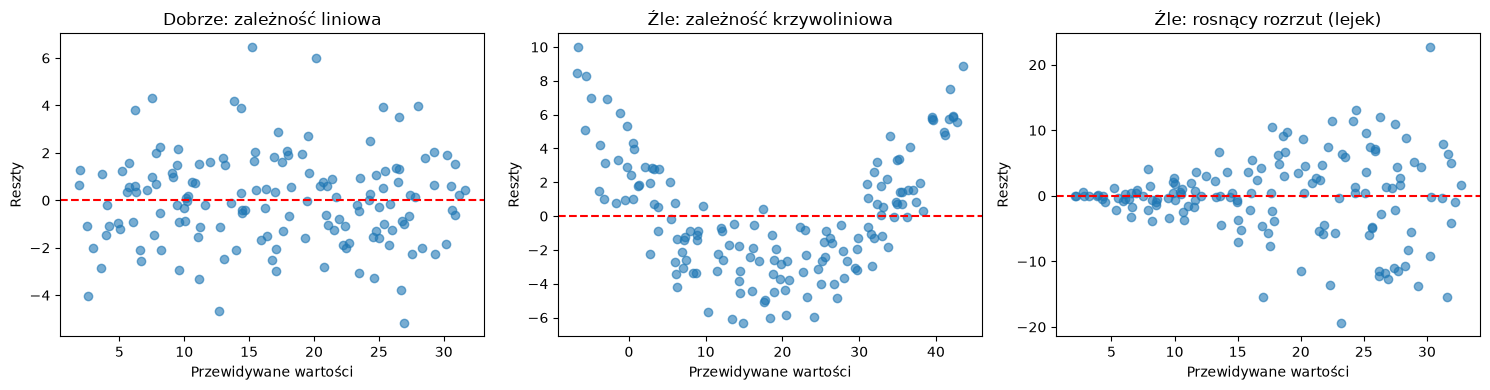

In [7]:
rng = np.random.default_rng(1)
x = rng.uniform(0, 10, 150).reshape(-1, 1)

zbiory = {
    'Dobrze: zależność liniowa': 2 + 3 * x[:, 0] + rng.normal(0, 2, 150),
    'Źle: zależność krzywoliniowa': 2 + 0.5 * x[:, 0] ** 2 + rng.normal(0, 2, 150),
    'Źle: rosnący rozrzut (lejek)': 2 + 3 * x[:, 0] + rng.normal(0, 1, 150) * x[:, 0],
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (tytul, yy) in zip(axes, zbiory.items()):
    m = LinearRegression().fit(x, yy)
    pred = m.predict(x)
    ax.scatter(pred, yy - pred, alpha=0.6)
    ax.axhline(0, color='red', linestyle='--')
    ax.set_title(tytul)
    ax.set_xlabel('Przewidywane wartości')
    ax.set_ylabel('Reszty')
plt.tight_layout()
plt.show()

**Jak czytać wykres reszt:**
- **Dobrze:** punkty rozrzucone losowo wokół zera, bez wzoru.
- **Łuk** (środek) – zależność nie jest liniowa. Rozwiązanie: dodać cechy nieliniowe (notatnik 05).
- **Lejek** (po prawej) – rozrzut reszt rośnie wraz z przewidywaniem, czyli wariancja nie jest stała.

Wykresy nie dają odpowiedzi „tak/nie”, ale szybko pokazują, czy model liniowy ma sens.

### 5.2 Normalność reszt

Wróćmy do modelu z sekcji 2. Rozkład reszt oceniamy histogramem, wykresem **Q-Q** (kwantyle reszt vs kwantyle rozkładu normalnego) i opcjonalnie testem Shapiro-Wilka.

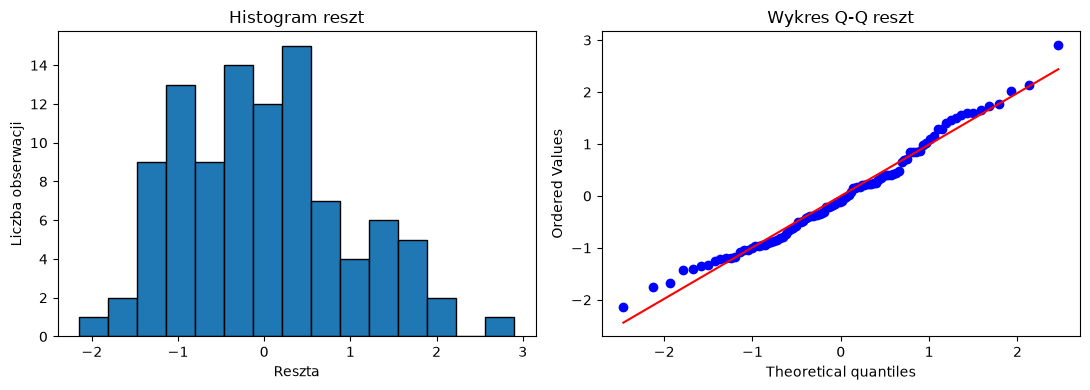

Test Shapiro-Wilka: statystyka = 0.982, p-value = 0.186


In [8]:
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(residuals, bins=15, edgecolor='black')
axes[0].set_title('Histogram reszt')
axes[0].set_xlabel('Reszta')
axes[0].set_ylabel('Liczba obserwacji')

stats.probplot(residuals, dist='norm', plot=axes[1])
axes[1].set_title('Wykres Q-Q reszt')

plt.tight_layout()
plt.show()

statistic, p_value = stats.shapiro(residuals)
print(f'Test Shapiro-Wilka: statystyka = {statistic:.3f}, p-value = {p_value:.3f}')

**Interpretacja:**
- **Wykres Q-Q:** dobrze, gdy punkty leżą blisko prostej. Odchylenia na końcach oznaczają „ciężkie ogony” (wartości odstające).
- **Test Shapiro-Wilka:** H0 = reszty mają rozkład normalny. Gdy `p-value > 0.05`, nie ma podstaw do odrzucenia normalności. Przy dużych próbach test jest bardzo czuły, dlatego zawsze oceniaj go razem z wykresami.

### 5.3 Współliniowość

Gdy dwie cechy niosą prawie tę samą informację (np. wzrost w cm i w calach), model nie potrafi rozdzielić ich wpływu i współczynniki stają się niestabilne. Dotyczy to regresji z **wieloma cechami** (notatnik 04). Wykrywamy ją macierzą korelacji lub wskaźnikiem VIF.

## 6. Pułapka ekstrapolacji

Model liniowy dobrze opisuje dane **w zakresie, na którym się uczył** (interpolacja). Poza tym zakresem (**ekstrapolacja**) prosta może prowadzić do absurdalnych wniosków.

![Ekstrapolacja](../obrazki/3.1_ekstrapolacja_xkcd.png)

Przykład z ekonomii: prognoza, kiedy PKB per capita Polski przegoni Wielką Brytanię. Wynik zależy od założonych stałych tempa wzrostu, a nie od faktów.

![PKB Polski i Wielkiej Brytanii](../obrazki/3.1_pib_polska_uk.png)

Materiał dodatkowy (wideo): [youtube.com/watch?v=sjusqc20oTo](https://www.youtube.com/watch?v=sjusqc20oTo)

## 7. Zalety i wady

**Zalety:**
- **Prostota** – łatwy start i szybkie wdrożenie.
- **Interpretowalność** – łatwo wyjaśnić wpływ cech na wynik.
- **Szybkość** – trening i predykcja zwykle trwają ułamki sekundy.
- **Dobry baseline** – punkt odniesienia dla bardziej złożonych modeli.

**Wady:**
- **Założenie liniowości** – nie każdą zależność opisze prosta.
- **Wrażliwość na wartości odstające** – kilka skrajnych punktów może mocno zmienić prostą.
- **Ekstrapolacja** – poza zakresem danych wyniki są zawodne.

## 8. Podsumowanie

1. Regresja liniowa to prosty i bardzo dobry model bazowy do przewidywania liczb.
2. Model znajduje parametry minimalizujące średni kwadrat reszt (MSE).
3. Sprawdzamy założenia, głównie na wykresie reszt: bez wzoru, o stałym rozrzucie.
4. Gdy założenia są mocno naruszone, dodajemy nowe cechy, transformujemy dane albo wybieramy inny model.
5. Nie wyciągamy wniosków poza zakresem danych treningowych.